# Laboratorio Final — Starbucks Rewards: del experimento a la decisión

Cierra el bloque de Churn y Uplift Modeling. Van a trabajar con la campaña COMPLETA (no una
muestra de prueba): 40,000 clientes, mitad recibió un cupón de $5 (tratamiento), mitad no
(control), medidos a 60 días.

Este laboratorio repite, sobre la base completa, lo que ya practicaron en los Breakout Rooms:

| Dónde lo vieron | Qué van a repetir aquí |
|---|---|
| Breakout 2 — Las dos ventanas | Un modelo de riesgo/churn, para targetear y ver la pérdida |
| Breakout 3 — Los 4 cuadrantes | El T-learner: dos modelos, uno por grupo |
| Breakout 4 — La curva Qini | Miden qué tan bien ordena su T-learner con datos que nunca vio |

Las columnas `recency_days`, `frequency` y `monetary` son las mismas del RFM de la Semana 1.

**Los 3 pasos del laboratorio:**
1. Entrenan un modelo de churn y lo usan para targetear — van a ver la pérdida con sus
   propios números.
2. Programan el T-learner y miden su Qini.
3. Deciden a quién contactar: eligen el porcentaje óptimo y defienden la cifra.

El dataset trae una columna oculta con el **tipo real de cada cliente y su uplift
verdadero** — en la vida real esa columna no existe. Al final del laboratorio la van a
destapar para ver si sus modelos acertaron.

Donde dice **`# TODO`** hay algo para que ustedes completen.


In [2]:
!mkdir -p data
!wget -q -O data/uplift_campaign.csv https://raw.githubusercontent.com/SindyBatzz/semana-3/main/Semana_3/Tarea/data/uplift_campaign.csv
!wget -q -O uplift_campaign_FULL.csv https://raw.githubusercontent.com/SindyBatzz/semana-3/main/Semana_3/Tarea/uplift_campaign_FULL.csv
!ls -lh data uplift_campaign_FULL.csv

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/uplift_campaign.csv")
print(f"{len(df):,} clientes · {(df['treatment_group']=='treatment').sum():,} tratados · {(df['treatment_group']=='control').sum():,} control")
df.head()


-rw-r--r-- 1 root root 2.9M Oct 12 19:12 uplift_campaign_FULL.csv

data:
total 2.1M
-rw-r--r-- 1 root root 2.1M Oct 12 19:12 uplift_campaign.csv
40,000 clientes · 19,921 tratados · 20,079 control


,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,tenure_days,responded_60d,value_60d,margin_60d,utilidad_neta_60d
0,1,treatment,15,25,615.42,0.230,998,1,38.86,9.72,4.67
1,2,control,30,7,196.12,0.231,551,1,57.20,14.30,14.30
2,3,control,37,1,151.60,0.428,508,0,0.00,0.00,0.00
3,4,control,0,16,449.54,0.386,733,1,24.21,6.05,6.05
4,5,treatment,20,10,393.00,0.796,734,1,23.62,5.91,0.86


## Paso 1 — entrenen un modelo de churn y usen para targetear

Un modelo de churn normal: no sabe nada de tratamiento/control, solo aprende a predecir quién
NO va a volver a comprar. Lo van a usar para elegir a quién contactar (targeting por riesgo) y
van a medir qué tan bien o mal les fue con esa decisión, usando el experimento real como juez.


In [3]:
FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate", "tenure_days"]

train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df["treatment_group"])

train_churn = train.copy()
train_churn["churned"] = 1 - train_churn["responded_60d"]

# Entrenamos el modelo de riesgo con los datos de entrenamiento y la variable objetivo
modelo_riesgo = LogisticRegression(max_iter=1000).fit(train_churn[FEATURES], train_churn["churned"])

test = test.copy()
test["prob_churn"] = modelo_riesgo.predict_proba(test[FEATURES])[:, 1]
print("Modelo de riesgo entrenado exitosamente")

Modelo de riesgo entrenado exitosamente


Ahora midan el valor real de targetear por riesgo: tomen el 30% con mayor probabilidad de
churn en el conjunto de prueba, y comparen el valor neto (`utilidad_neta_60d` para los
tratados de ese grupo, contra `margin_60d` del control de ese mismo grupo — su "costo de no
hacer nada").


In [4]:
def valor_de_la_politica(test_df, seleccionados):
    # Valor NETO: margen bruto menos el costo del cupón ($5, solo si compró) y el envío
    # ($0.05, por cualquier tratado) -- la misma fórmula de la slide "El experimento".
    sel = test_df.loc[seleccionados]
    valor_tratado = sel.loc[sel["treatment_group"] == "treatment", "utilidad_neta_60d"].mean()
    valor_control = sel.loc[sel["treatment_group"] == "control", "margin_60d"].mean()
    return valor_tratado - valor_control, len(sel)

n_contactar = int(len(test) * 0.30)
idx_riesgo = test.sort_values("prob_churn", ascending=False).head(n_contactar).index
uplift_riesgo, n_riesgo = valor_de_la_politica(test, idx_riesgo)
print(f"Targeting por riesgo: ${uplift_riesgo:+.2f}/cliente sobre {n_riesgo:,} clientes (total ${uplift_riesgo*n_riesgo:+,.2f})")

Targeting por riesgo: $+0.07/cliente sobre 3,600 clientes (total $+245.40)


## Paso 2 — programen el T-learner y midan su Qini

Dos modelos de **Regresión Logística**: uno entrenado SOLO con los clientes tratados de entrenamiento, otro SOLO con los
de control. Le preguntan a los dos sobre el conjunto de prueba completo, y restan.


In [5]:
train_t = train[train["treatment_group"] == "treatment"]
train_c = train[train["treatment_group"] == "control"]

# Entrenamos los dos modelos del T-learner utilizando LogisticRegression
modelo_tratado = LogisticRegression(max_iter=1000).fit(train_t[FEATURES], train_t["responded_60d"])
modelo_control = LogisticRegression(max_iter=1000).fit(train_c[FEATURES], train_c["responded_60d"])

X_test = test[FEATURES]
# Evaluamos las probabilidades de respuesta de ambos modelos sobre el grupo de prueba
test["p_tratado"] = modelo_tratado.predict_proba(X_test)[:, 1]
test["p_control"] = modelo_control.predict_proba(X_test)[:, 1]
test["uplift_estimado"] = test["p_tratado"] - test["p_control"]

print("T-learner entrenado y conjunto de prueba puntuado exitosamente")

T-learner entrenado y conjunto de prueba puntuado exitosamente


In [6]:
def curva_qini(test_df, score_col, steps=40):
    orden = test_df.sort_values(score_col, ascending=False).reset_index(drop=True)
    es_tratado = (orden["treatment_group"] == "treatment").values
    respondio = orden["responded_60d"].values

    acumulado_tratados = np.cumsum(np.where(es_tratado, respondio, 0))
    acumulado_control = np.cumsum(np.where(~es_tratado, respondio, 0))
    n_tratados_acum = np.cumsum(es_tratado)
    n_control_acum = np.cumsum(~es_tratado)

    n = len(orden)
    xs, ys = [0.0], [0.0]
    for i in np.linspace(1, n, steps).astype(int):
        nt, nc = n_tratados_acum[i - 1], n_control_acum[i - 1]
        tasa_t = acumulado_tratados[i - 1] / nt if nt > 0 else 0
        tasa_c = acumulado_control[i - 1] / nc if nc > 0 else 0
        xs.append(i / n)
        ys.append((tasa_t - tasa_c) * n)
    return np.array(xs), np.array(ys)


def coeficiente_qini(xs, ys, n):
    area_modelo = np.trapezoid(ys, xs)
    area_azar = np.trapezoid(np.linspace(0, ys[-1], len(xs)), xs)
    return (area_modelo - area_azar) / n


xs_uplift, ys_uplift = curva_qini(test, "uplift_estimado")
xs_riesgo, ys_riesgo = curva_qini(test, "prob_churn")
qini_uplift = coeficiente_qini(xs_uplift, ys_uplift, len(test))
qini_riesgo = coeficiente_qini(xs_riesgo, ys_riesgo, len(test))

print(f"Coeficiente Qini · T-learner:       {qini_uplift:+.3f}")
print(f"Coeficiente Qini · riesgo/churn:    {qini_riesgo:+.3f}")

Coeficiente Qini · T-learner:       +0.142
Coeficiente Qini · riesgo/churn:    +0.048


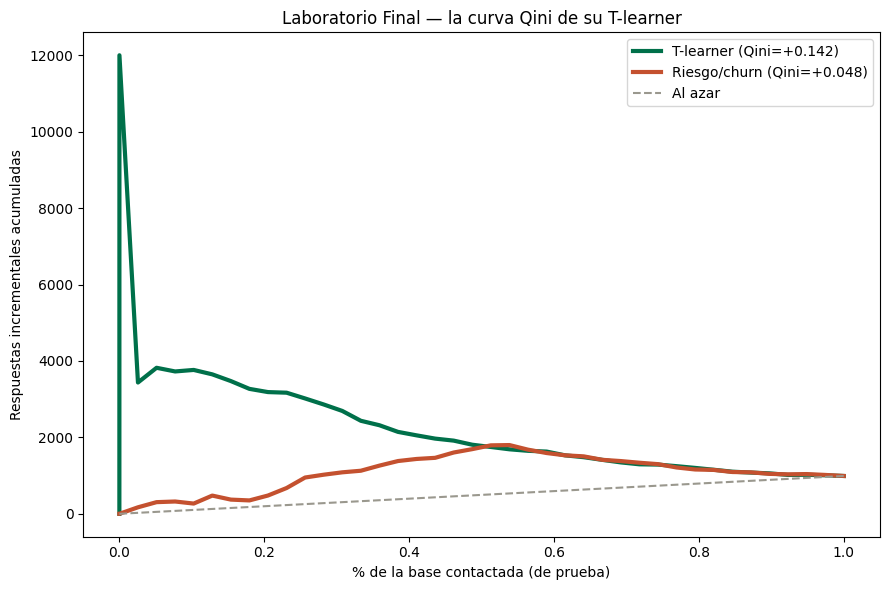

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(xs_uplift, ys_uplift, color="#00704A", linewidth=3, label=f"T-learner (Qini={qini_uplift:+.3f})")
ax.plot(xs_riesgo, ys_riesgo, color="#C4512F", linewidth=3, label=f"Riesgo/churn (Qini={qini_riesgo:+.3f})")
ax.plot([0, 1], [0, ys_uplift[-1]], color="#9A988E", linestyle="--", label="Al azar")
ax.set_xlabel("% de la base contactada (de prueba)")
ax.set_ylabel("Respuestas incrementales acumuladas")
ax.set_title("Laboratorio Final — la curva Qini de su T-learner")
ax.legend()
plt.tight_layout()
plt.savefig("curva_qini_laboratorio.png", dpi=150)
plt.show()

## Paso 3 — decidan a quién contactar

Prueben varios porcentajes de la base (10%, 20%, ..., 100%) ordenados por `uplift_estimado`, y
para cada uno calculen el valor neto total (usando `value_60d`, igual que en el Paso 2).
Encuentren el porcentaje que deja más dinero sobre la mesa.


In [8]:
resultados = []
for pct in range(10, 101, 10):
    n_c = int(len(test) * pct / 100)
    idx = test.sort_values("uplift_estimado", ascending=False).head(n_c).index
    valor_cliente, n = valor_de_la_politica(test, idx)
    resultados.append({"pct_contactado": pct, "valor_por_cliente": round(valor_cliente, 2), "n_contactados": n, "valor_total": round(valor_cliente * n, 2)})

tabla_politicas = pd.DataFrame(resultados)
tabla_politicas

,pct_contactado,valor_por_cliente,n_contactados,valor_total
0,10,1.62,1200,1948.93
1,20,0.99,2400,2368.51
2,30,0.46,3600,1673.33
3,40,-0.10,4800,-500.97
4,50,-0.48,6000,-2899.72
5,60,-0.73,7200,-5260.88
6,70,-0.93,8400,-7853.02
7,80,-1.17,9600,-11226.84
8,90,-1.45,10800,-15687.26
9,100,-1.69,12000,-20236.13


**Pregunta para defender con su propia cifra:** ¿cuál % maximiza el valor TOTAL? ¿Es el mismo
que maximiza el valor POR CLIENTE? ¿Por qué no, necesariamente?

El valor TOTAL se maximiza contactando al 20% de la base ($2,368.51).

 Pero el valor por cliente se maximiza en el 10% ($1.62 por cliente).

 No coinciden porque al ampliar del 10% al 20% entran clientes con menor uplift: eso baja el promedio ($1.62 → $0.99), pero cada uno de esos clientes adicionales todavía aporta valor positivo, así que el total sigue subiendo. A partir del 30% empiezan a entrar *sleeping dogs* y *lost causes*, el cliente marginal destruye valor y el total cae (y desde el 40% es negativo). La decisión correcta es la que maximiza el total, no el promedio.


## La revelación final

Esta es la parte que no pudieron hacer en los Breakout Rooms: el dataset completo
(`uplift_campaign_FULL.csv`) trae el **tipo real** de cada cliente y su **uplift verdadero** —
información que en la vida real nunca existe. Compárenla contra lo que su modelo estimó.


In [9]:
full = pd.read_csv("uplift_campaign_FULL.csv")
full_test = full[full["customer_id"].isin(test["customer_id"])].merge(
    test[["customer_id", "uplift_estimado", "prob_churn"]], on="customer_id"
)

print("Composición real de la base de prueba:")
print((full_test["true_type"].value_counts(normalize=True) * 100).round(1))
print()
print("Correlación entre uplift ESTIMADO y uplift VERDADERO:", round(full_test["uplift_estimado"].corr(full_test["true_uplift_prob"]), 3))


Composición real de la base de prueba:
true_type
sure_thing      48.9
persuadable     22.4
lost_cause      21.5
sleeping_dog     7.2
Name: proportion, dtype: float64

Correlación entre uplift ESTIMADO y uplift VERDADERO: 0.619


**Interpretación:** La correlación de 0.619 entre el uplift estimado y el verdadero indica que el T-learner logístico ordena razonablemente bien a los clientes, aunque no perfecto. Solo el 22.4% de la base son *persuadables* (los únicos a quienes el cupón les cambia la decisión) y un 7.2% son *sleeping dogs*, que reaccionan negativamente a ser contactados. Por eso contactar a más del 20–30% de la base destruye valor: casi la mitad (48.9%) son *sure things* que iban a comprar de todos modos, y el cupón solo nos cuesta dinero con ellos.

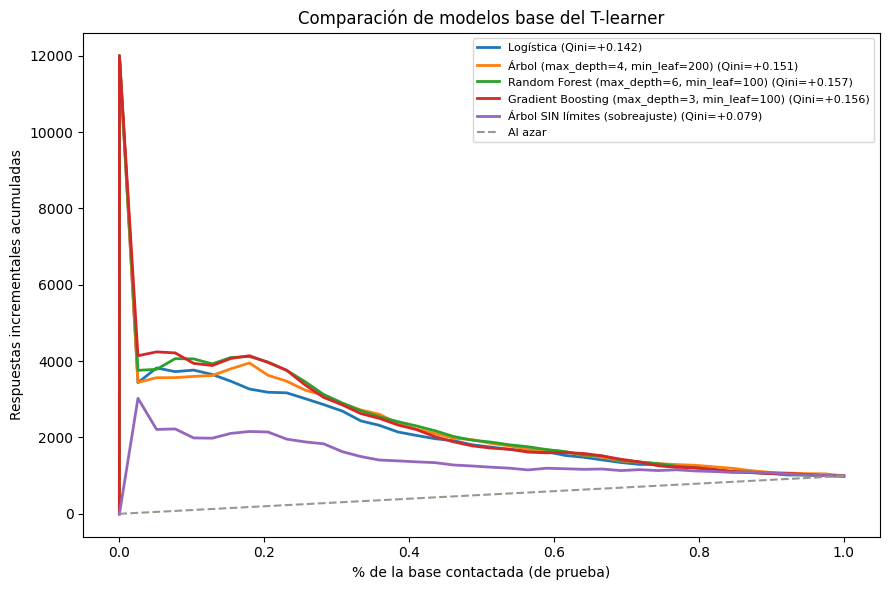

,Modelo base,Qini,Correlación con uplift real,Mejor %,Valor total en mejor %
2,"Random Forest (max_depth=6, min_leaf=100)",0.157,0.857,20,4433.80
3,"Gradient Boosting (max_depth=3, min_leaf=100)",0.156,0.848,20,4485.16
1,"Árbol (max_depth=4, min_leaf=200)",0.151,0.748,20,3565.92
0,Logística,0.142,0.619,20,2368.51
4,Árbol SIN límites (sobreajuste),0.079,0.204,10,-830.66


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

modelos_base = {
    "Logística": lambda: LogisticRegression(max_iter=1000),
    "Árbol (max_depth=4, min_leaf=200)": lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=42),
    "Random Forest (max_depth=6, min_leaf=100)": lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=100, random_state=42, n_jobs=-1),
    "Gradient Boosting (max_depth=3, min_leaf=100)": lambda: GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, min_samples_leaf=100, random_state=42),
    "Árbol SIN límites (sobreajuste)": lambda: DecisionTreeClassifier(random_state=42),
}

verdad = full[["customer_id", "true_uplift_prob"]]
comparacion = []
plt.figure(figsize=(9, 6))

for nombre, crear in modelos_base.items():
    m_t = crear().fit(train_t[FEATURES], train_t["responded_60d"])
    m_c = crear().fit(train_c[FEATURES], train_c["responded_60d"])
    t = test.copy()
    t["uplift_m"] = m_t.predict_proba(t[FEATURES])[:, 1] - m_c.predict_proba(t[FEATURES])[:, 1]

    xs, ys = curva_qini(t, "uplift_m")
    qini = coeficiente_qini(xs, ys, len(t))
    corr = t[["customer_id", "uplift_m"]].merge(verdad, on="customer_id")[["uplift_m", "true_uplift_prob"]].corr().iloc[0, 1]

    orden = t.sort_values("uplift_m", ascending=False)
    totales = {pct: valor_de_la_politica(t, orden.head(int(len(t) * pct / 100)).index) for pct in range(10, 101, 10)}
    mejor_pct = max(totales, key=lambda p: totales[p][0] * totales[p][1])

    comparacion.append({"Modelo base": nombre, "Qini": round(qini, 3), "Correlación con uplift real": round(corr, 3),
                        "Mejor %": mejor_pct, "Valor total en mejor %": round(totales[mejor_pct][0] * totales[mejor_pct][1], 2)})
    plt.plot(xs, ys, linewidth=2, label=f"{nombre} (Qini={qini:+.3f})")

plt.plot([0, 1], [0, ys_uplift[-1]], color="#9A988E", linestyle="--", label="Al azar")
plt.xlabel("% de la base contactada (de prueba)"); plt.ylabel("Respuestas incrementales acumuladas")
plt.title("Comparación de modelos base del T-learner"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

pd.DataFrame(comparacion).sort_values("Qini", ascending=False)

**Respuesta:** Random Forest y Gradient Boosting son los que más mejoran: el Qini sube de 0.142 a ~0.157 y la correlación con el uplift real sube de 0.619 a ~0.85. Esto pasa porque capturan relaciones no lineales entre las variables que la regresión logística no ve. En dinero, contactando al mismo 20%, el valor total casi se duplica (de $2,369 a ~$4,450). El árbol SIN límites muestra el riesgo del sobreajuste: memoriza el entrenamiento y su Qini cae a 0.079, con correlación de 0.204 y valor negativo. Por eso es clave limitar max_depth y min_samples_leaf.

## Conclusión — Recomendación para la campaña de cupones Starbucks Rewards

**Para:** Presidente de Marketing
**Asunto:** A quién enviar el cupón de $5 en la próxima campaña

### Recomendación
Enviar el cupón únicamente al **20% de los clientes** que nuestro modelo identifica como más influenciables por la promoción, y no a toda la base.

### Por qué
Analizamos la campaña completa: 40,000 clientes, la mitad recibió el cupón y la otra mitad no, medidos durante 60 días. Esto nos permitió medir cuántas compras generó realmente el cupón, y no solo cuántas ocurrieron.

El hallazgo principal es que **la mayoría de los clientes no necesita el cupón**:
- **49%** iba a comprar de todos modos. Darles el cupón es regalar $5.
- **22%** no compra aunque reciba el cupón.
- **7%** reacciona negativamente al ser contactado y compra menos.
- Solo **22%** son clientes a quienes el cupón realmente les cambia la decisión.

Por eso, contactar a toda la base **pierde dinero**: estimamos unos **$67,000 de pérdida** por campaña si se extrapola a los 40,000 clientes. Enfocarse en el 20% correcto genera ganancia.

### Comparación de estrategias (valor neto estimado sobre la base completa)
| Estrategia | Resultado estimado |
|---|---|
| Enviar cupón a todos | **−$67,000** |
| Enviar al 30% con más riesgo de abandono (práctica habitual) | +$800 |
| Enviar al 20% más influenciable (modelo inicial) | +$7,900 |
| **Enviar al 20% más influenciable (modelo recomendado)** | **+$14,800** |

La práctica habitual de dirigirse a los clientes "en riesgo de irse" casi no genera valor, porque que un cliente esté en riesgo no significa que el cupón lo vaya a retener.

### ¿Qué tan confiable es el modelo?
Contrastamos las predicciones contra el comportamiento real de cada cliente, información que normalmente no está disponible y que en este ejercicio sí teníamos. El modelo inicial acertó razonablemente en el orden de los clientes (correlación de 0.62). Al probar modelos más avanzados (Random Forest), la precisión subió a **0.86**, lo que **casi duplica la ganancia** con el mismo número de cupones. También confirmamos que un modelo sin controles "memoriza" los datos y termina perdiendo dinero, por lo que la versión recomendada incluye esos controles.

### Próximos pasos
1. Aplicar el modelo recomendado en la próxima campaña, contactando solo al 20% seleccionado.
2. Mantener un pequeño grupo sin cupón para seguir midiendo el impacto real.
3. Reentrenar el modelo cada trimestre con los resultados nuevos.